In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.datasets import make_moons


In [2]:
D = 2
N = 2_000
SEED = 42
DEVICE = 'cpu'

steps = 100
batch_size = 256
lr = 1e-3
eps_max = 0.05

np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
def sample_data(batch_size,):
    return sample_moon(batch_size)

def sample_moon(batch_size):
    X, y = make_moons(batch_size, noise=0.1)
    return torch.from_numpy(X).float()

def sample_blobs(batch_size, n_modes=8, radius=2.0, std=0.1):
    angles = torch.randint(0, n_modes, (batch_size,)).float() * (2 * 3.14159265 / n_modes)
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1) + 0.5
    return centers + std * torch.randn(batch_size, 2)
 
def sample_noise(batch_size):
    return sample_blobs(batch_size)
    # return torch.randn(batch_size, D)

In [4]:
class EBM(nn.Module):
    def __init__(self, dim = 2, hidden_dim = 256):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.net(x)

def grad_V(V, x):
    x = x.detach().requires_grad_(True)
    energy = V(x).sum()
    (g, ) = torch.autograd.grad(energy, x, create_graph=True)
    return g

def langevin_negative_samples(V, x_init, n_steps = 50, steps_size = 0.01, eps_max=0.05):
    x = x_init.clone().detach()
    for _ in range(n_steps):
        g = grad_V(V, x).detach()
        noise = torch.randn_like(x)

        x = x - steps_size * g + (2 * steps_size * eps_max) ** 0.5 * noise
        x = x.detach()

    return x

def loss(V, batch_size, eps_max=0.05, alpha=0.1):
    x_data = sample_data(batch_size)
    x0 = sample_noise(batch_size)

    x_neg = langevin_negative_samples(V, x0, eps_max=eps_max)

    v_data = V(x_data)
    v_neg = V(x_neg)

    cd_loss = V(x_data).mean() / eps_max - V(x_neg).mean() / eps_max
    reg = alpha *  (v_data ** 2 + v_neg ** 2).mean()

    return cd_loss + reg

In [5]:
V = EBM(dim=D)
opt = torch.optim.Adam(V.parameters(), lr=lr)

V.train()

losses = []

with tqdm(range(steps)) as pb:
    for i in pb:
        opt.zero_grad()
        l = loss(V, batch_size, eps_max)
        l.backward()
        opt.step()

        pb.set_postfix({'Loss': f'{l.item():.2f}'})
        losses.append(l.item())

100%|██████████| 100/100 [00:09<00:00, 10.58it/s, Loss=0.77]


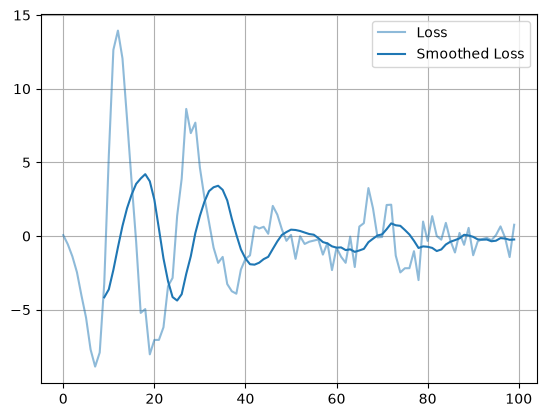

In [6]:
fig, ax = plt.subplots()

ax.plot(losses, label="Loss", color="tab:blue", alpha=0.5)
ws = 10
smoothed = np.convolve(losses, np.ones(ws) / ws, mode="valid")
ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed Loss", color="tab:blue")
# ax.set_yscale('log')

plt.legend()
plt.grid()
plt.show()

In [7]:
@torch.no_grad()
def sample(V, n_samples, eps_max=0.05):
    x = sample_noise(n_samples)
    with torch.enable_grad():
        x = langevin_negative_samples(V, x, eps_max=eps_max)

    return x

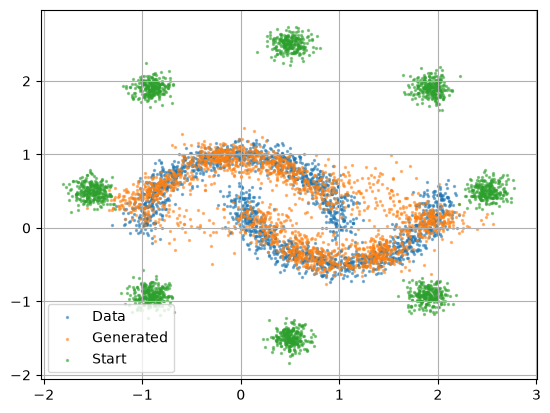

In [8]:
V.eval()

data = sample_data(N)
samples = sample(V, n_samples=N)
blobs = sample_blobs(N)

fig, ax = plt.subplots()

ax.scatter(data[:, 0], data[:, 1], alpha=0.5, s=2, label="Data")
ax.scatter(samples[:, 0], samples[:, 1], alpha=0.5, s=2, label="Generated")
ax.scatter(blobs[:, 0], blobs[:, 1], alpha=0.5, s=2, label="Start")

plt.legend()
plt.grid()
plt.show()

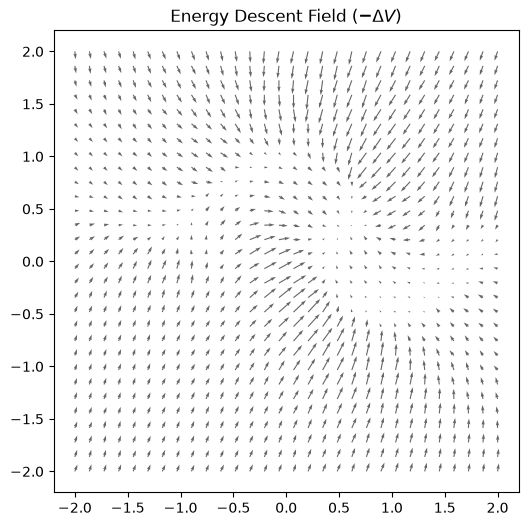

In [9]:
def plot_energy_gradient_field(ax, V, x_range=(-2, 2), y_range=(-2, 2), n_grid=30):
    xs = np.linspace(*x_range, n_grid)
    ys = np.linspace(*y_range, n_grid)
    xx, yy = np.meshgrid(xs, ys)

    grid = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32)

    g = grad_V(V, grid).detach().numpy()

    u = -g[:, 0].reshape(n_grid, n_grid)
    v = -g[:, 1].reshape(n_grid, n_grid)

    ax.quiver(xx, yy, u, v, color="black", alpha=0.6)
    ax.set_title(r"Energy Descent Field ($-\Delta V$)")


fig, ax = plt.subplots(figsize=(6,6))
plot_energy_gradient_field(ax, V)

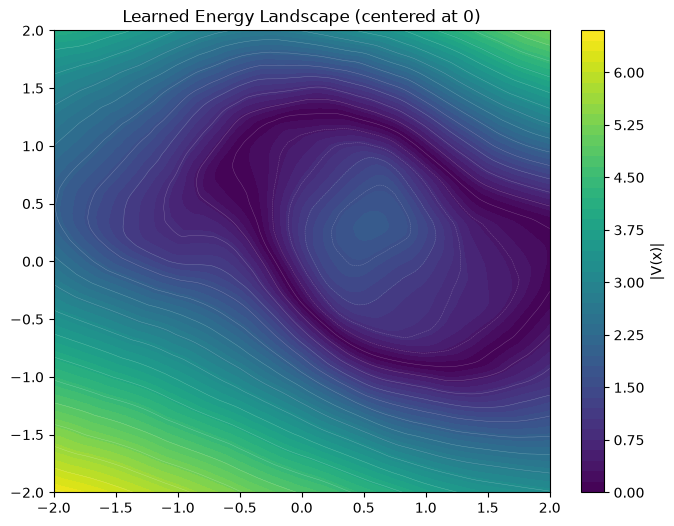

In [10]:
@torch.no_grad()
def plot_energy_landscape(ax, V, x_range=(-2, 2), y_range=(-2, 2), n_grid=200):
    xs = np.linspace(*x_range, n_grid)
    ys = np.linspace(*y_range, n_grid)
    xx, yy = np.meshgrid(xs, ys)

    grid = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32)
    energy = V(grid).squeeze(-1).reshape(n_grid, n_grid).numpy()

    energy_abs = np.abs(energy)
    cf = ax.contourf(xx, yy, energy_abs, levels=50, cmap="viridis", vmin=0)
    plt.colorbar(cf, ax=ax, label="|V(x)|")
    ax.contour(xx, yy, energy, levels=20, colors="white", linewidths=0.3, alpha=0.3)

    ax.set_title("Learned Energy Landscape (centered at 0)")


fig, ax = plt.subplots(figsize=(8, 6))
plot_energy_landscape(ax, V)
plt.show()